In [ ]:
import os
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

import joblib

print("✅ ALL LIBRARIES IMPORTED SUCCESSFULLY!")

✅ ALL LIBRARIES IMPORTED SUCCESSFULLY!


In [ ]:
import os
import pandas as pd

# Move from outputs folder to the main Titanic_ML_Project folder
PROJECT_DIR = os.path.dirname(os.getcwd())

print("Project folder:")
print(PROJECT_DIR)

# Load datasets
train = pd.read_csv(
    os.path.join(PROJECT_DIR, "data", "train.csv")
)

test = pd.read_csv(
    os.path.join(PROJECT_DIR, "data", "test.csv")
)

print("\nTraining Dataset Shape:", train.shape)
print("Test Dataset Shape:", test.shape)

display(train.head())


Project folder:
c:\Users\mouni\OneDrive\Desktop\Titanic_ML_Project

Training Dataset Shape: (891, 12)
Test Dataset Shape: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Dataset Understanding

In [ ]:
print("=" * 70)
print("DATASET UNDERSTANDING")
print("=" * 70)

print("\nFirst 5 rows:")
display(train.head())

print("\nColumn Names:")
print(train.columns.tolist())

print("\nData Types:")
print(train.dtypes)

print("\nStatistical Summary:")
display(train.describe())

DATASET UNDERSTANDING

First 5 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Data Types:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

Statistical Summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Missing Value Analysis

In [ ]:
print("=" * 70)
print("MISSING VALUE ANALYSIS")
print("=" * 70)

print("\nMissing values:")
print(train.isnull().sum())

print("\nMissing value percentage:")

missing_percentage = (
    train.isnull().sum() / len(train) * 100
).round(2)

display(missing_percentage)

MISSING VALUE ANALYSIS

Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Missing value percentage:


PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
dtype: float64

Duplicate Check

In [ ]:
print("=" * 70)
print("DUPLICATE CHECK")
print("=" * 70)

duplicate_count = train.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

DUPLICATE CHECK
Number of duplicate rows: 0


Target Variable Analysis

In [ ]:
print("=" * 70)
print("TARGET VARIABLE ANALYSIS")
print("=" * 70)

print("\nSurvival Count:")
print(train["Survived"].value_counts())

print("\nSurvival Percentage:")
print(
    train["Survived"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

TARGET VARIABLE ANALYSIS

Survival Count:
Survived
0    549
1    342
Name: count, dtype: int64

Survival Percentage:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


Survival Distribution

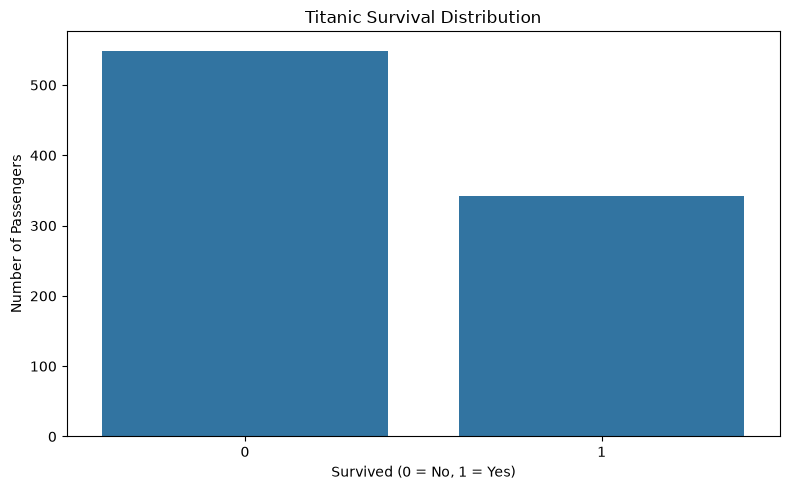

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data=train, x="Survived")

plt.title("Titanic Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.show()

Survival by Gender

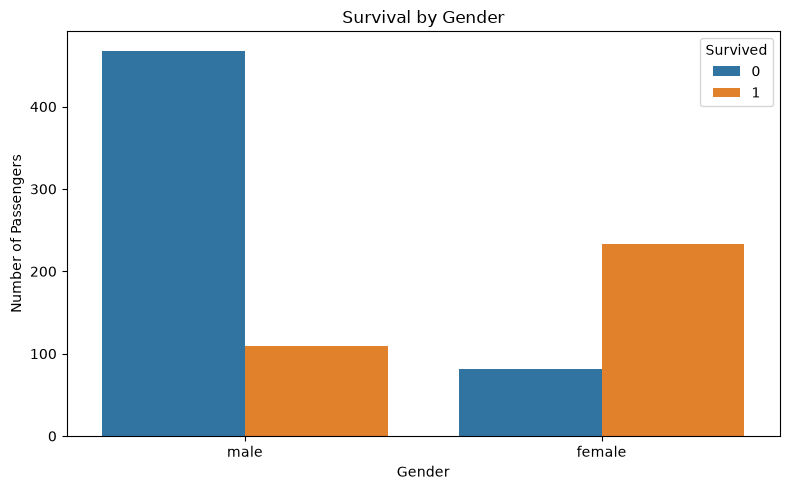

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train,
    x="Sex",
    hue="Survived"
)

plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.show()

Survival by Passenger Class

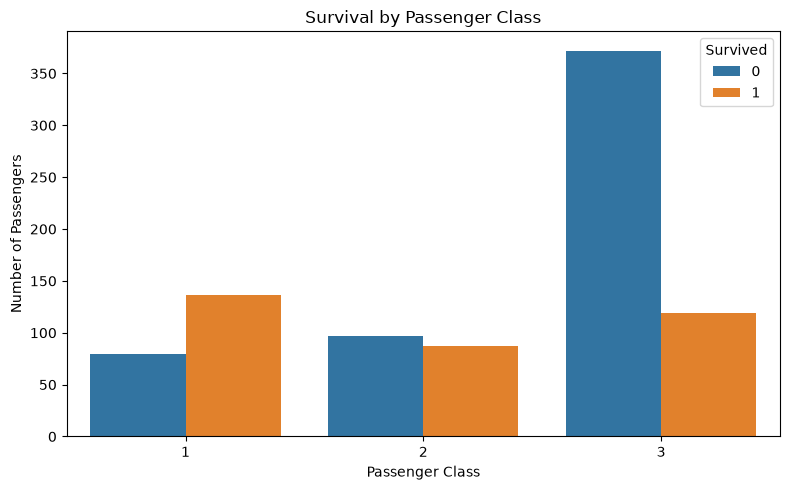

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train,
    x="Pclass",
    hue="Survived"
)

plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.show()

Age Distribution

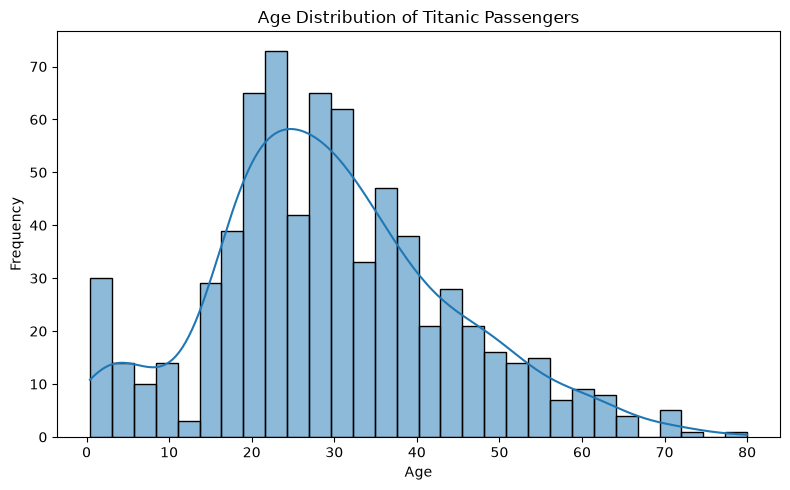

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=train,
    x="Age",
    bins=30,
    kde=True
)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Fare Distribution

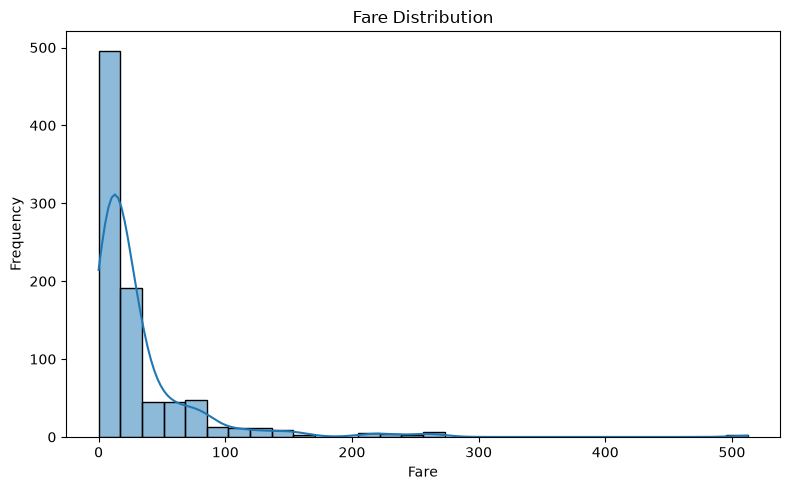

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=train,
    x="Fare",
    bins=30,
    kde=True
)

plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Survival by Embarked

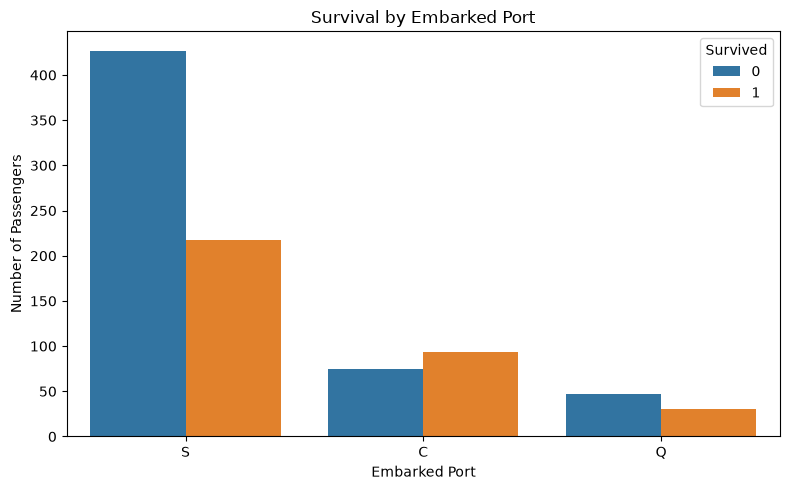

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train,
    x="Embarked",
    hue="Survived"
)

plt.title("Survival by Embarked Port")
plt.xlabel("Embarked Port")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.show()

Correlation Heatmap

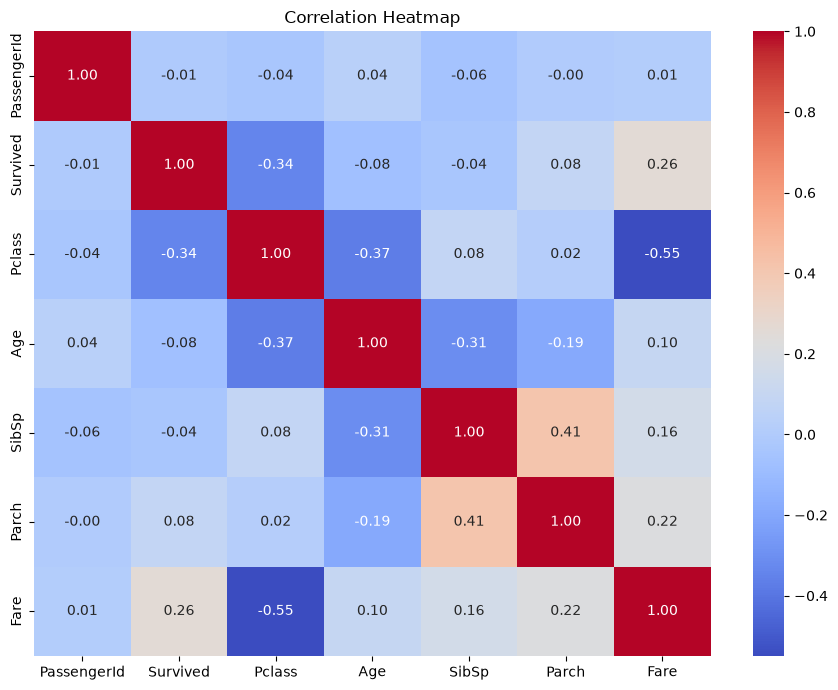

In [ ]:
numeric_data = train.select_dtypes(include=np.number)

plt.figure(figsize=(9, 7))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

Data Preprocessing

In [ ]:
train_processed = train.copy()
test_processed = test.copy()

print("Training copy:", train_processed.shape)
print("Testing copy:", test_processed.shape)

Training copy: (891, 12)
Testing copy: (418, 11)


CabinKnown

In [ ]:
train_processed["CabinKnown"] = (
    train_processed["Cabin"].notna().astype(int)
)

test_processed["CabinKnown"] = (
    test_processed["Cabin"].notna().astype(int)
)

display(
    train_processed[["Cabin", "CabinKnown"]].head(10)
)

,Cabin,CabinKnown
0,NaN,0
1,C85,1
2,NaN,0
3,C123,1
4,NaN,0
5,NaN,0
6,E46,1
7,NaN,0
8,NaN,0
9,NaN,0


Feature Engineering

In [ ]:
def create_features(df):
    df = df.copy()

    # Family size
    df["FamilySize"] = (
        df["SibSp"] +
        df["Parch"] +
        1
    )

    # Is passenger alone?
    df["IsAlone"] = (
        df["FamilySize"] == 1
    ).astype(int)

    # Extract passenger title
    df["Title"] = (
        df["Name"]
        .str.extract(r",\s*([^.]*)\.", expand=False)
        .str.strip()
    )

    # Group uncommon titles
    common_titles = [
        "Mr",
        "Miss",
        "Mrs",
        "Master"
    ]

    df["Title"] = df["Title"].apply(
        lambda x: x if x in common_titles else "Rare"
    )

    return df

Apply Feature Engineering

In [ ]:
train_processed = create_features(train_processed)
test_processed = create_features(test_processed)

display(
    train_processed[
        [
            "FamilySize",
            "IsAlone",
            "Title",
            "CabinKnown"
        ]
    ].head()
)

,FamilySize,IsAlone,Title,CabinKnown
0,2,0,Mr,0
1,2,0,Mrs,1
2,1,1,Miss,0
3,2,0,Mrs,1
4,1,1,Mr,0


Feature Selection

In [ ]:
drop_columns = [
    "PassengerId",
    "Name",
    "Ticket",
    "Cabin",
    "Survived"
]

X = train_processed.drop(
    columns=drop_columns
)

y = train_processed["Survived"]

X_unseen = test_processed.drop(
    columns=[
        "PassengerId",
        "Name",
        "Ticket",
        "Cabin"
    ]
)

print("Features:")
print(X.columns.tolist())

print("\nX:", X.shape)
print("y:", y.shape)
print("Test:", X_unseen.shape)

Features:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'CabinKnown', 'FamilySize', 'IsAlone', 'Title']

X: (891, 11)
y: (891,)
Test: (418, 11)


Feature Types

In [ ]:
numeric_features = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize",
    "IsAlone",
    "CabinKnown"
]

categorical_features = [
    "Sex",
    "Embarked",
    "Title"
]

print("Numeric Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numeric Features:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'CabinKnown']

Categorical Features:
['Sex', 'Embarked', 'Title']


Train Validation Split

In [ ]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Validation:", X_valid.shape)

Training: (712, 11)
Validation: (179, 11)


Numerical Pipeline

In [ ]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

print("Numerical pipeline created.")

Numerical pipeline created.


Categorical Pipeline

In [ ]:
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

print("Categorical pipeline created.")

Categorical pipeline created.


Column Transformer

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


MODEL TRAINING
 Create Models

In [ ]:
models = {

    "Logistic Regression":
        LogisticRegression(max_iter=1000),

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=200,
            random_state=42
        ),

    "KNN":
        KNeighborsClassifier(
            n_neighbors=5
        ),

    "Gradient Boosting":
        GradientBoostingClassifier(
            random_state=42
        )
}

print("Models created:")
for name in models:
    print("-", name)

Models created:
- Logistic Regression
- Decision Tree
- Random Forest
- KNN
- Gradient Boosting


Train All Models

In [ ]:
results = []
trained_models = {}

for model_name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(
        X_train,
        y_train
    )

    y_pred = pipeline.predict(
        X_valid
    )

    y_prob = pipeline.predict_proba(
        X_valid
    )[:, 1]

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_valid, y_pred
        ),
        "Precision": precision_score(
            y_valid, y_pred
        ),
        "Recall": recall_score(
            y_valid, y_pred
        ),
        "F1 Score": f1_score(
            y_valid, y_pred
        ),
        "ROC-AUC": roc_auc_score(
            y_valid, y_prob
        )
    })

    trained_models[model_name] = pipeline

    print(
        model_name,
        "trained successfully."
    )

Logistic Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.
KNN trained successfully.
Gradient Boosting trained successfully.


Model Comparison

In [ ]:
results_df.to_csv(
    "results/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


Cross Validation

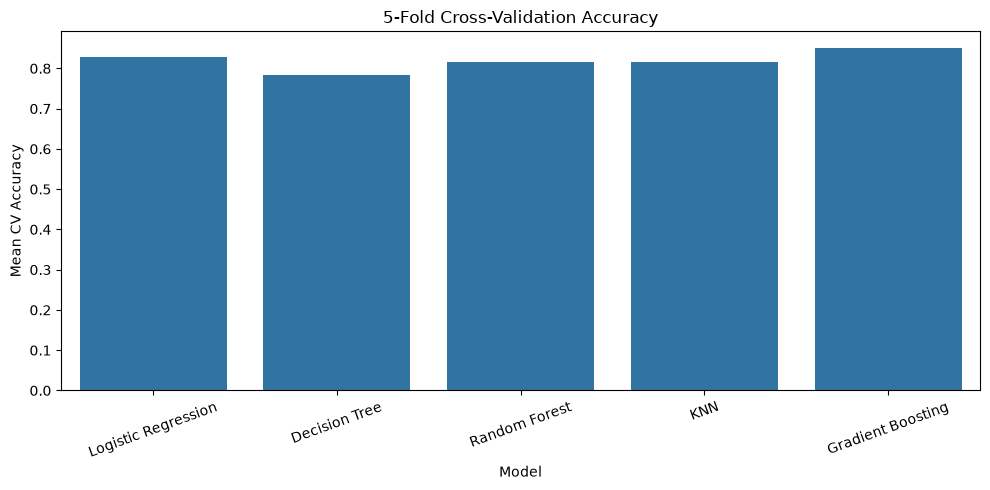

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=cv_df,
    x="Model",
    y="Mean CV Accuracy"
)

plt.title("5-Fold Cross-Validation Accuracy")
plt.xlabel("Model")
plt.ylabel("Mean CV Accuracy")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

HYPERPARAMETER TUNING
 Random Forest Pipeline

In [ ]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                random_state=42
            )
        )
    ]
)

Parameter Grid

In [ ]:
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_split": [2, 5]
}

print("Parameter grid created!")

Parameter grid created!


GridSearchCV

In [ ]:
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

print("Starting GridSearchCV...")

grid_search.fit(X_train, y_train)

print("\nGridSearchCV completed!")
print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest CV Accuracy:",
      round(grid_search.best_score_, 4))

Starting GridSearchCV...

GridSearchCV completed!

Best Parameters:
{'model__max_depth': 5, 'model__min_samples_split': 2, 'model__n_estimators': 100}

Best CV Accuracy: 0.8273


Best Model Prediction

In [ ]:
best_model = grid_search.best_estimator_

tuned_pred = best_model.predict(X_valid)

tuned_prob = best_model.predict_proba(X_valid)[:, 1]

print("Tuned model prediction completed!")

Tuned model prediction completed!


Tuned Model Evaluation

In [ ]:
tuned_accuracy = accuracy_score(y_valid, tuned_pred)

print("Tuned Random Forest Accuracy:",
      round(tuned_accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_valid, tuned_pred))

Tuned Random Forest Accuracy: 0.8156

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.87      0.85       110
           1       0.78      0.72      0.75        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



Confusion Matrix

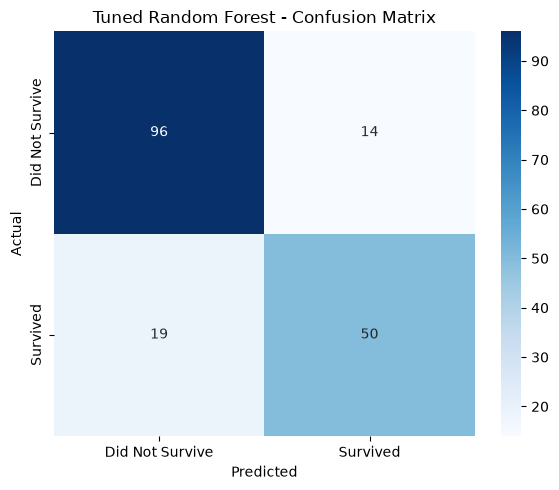

In [ ]:
cm = confusion_matrix(y_valid, tuned_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Did Not Survive", "Survived"],
    yticklabels=["Did Not Survive", "Survived"]
)

plt.title("Tuned Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

ROC Curve

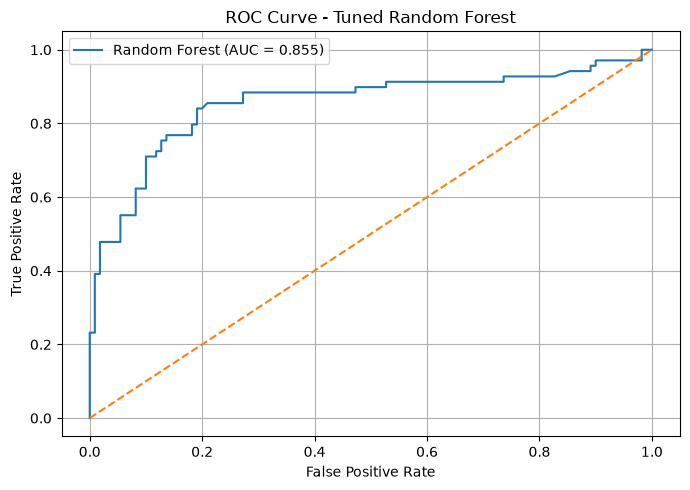

ROC-AUC Score: 0.8548


In [ ]:
fpr, tpr, thresholds = roc_curve(y_valid, tuned_prob)

roc_auc = roc_auc_score(y_valid, tuned_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Random Forest")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

print("ROC-AUC Score:", round(roc_auc, 4))

Model Comparison

In [ ]:

# Tuned Random Forest accuracy
tuned_accuracy = accuracy_score(y_valid, tuned_pred)

# Compare with models that have already been evaluated
results = []

# Check which model variables exist
if 'logistic_model' in globals():
    pred = logistic_model.predict(X_valid)
    results.append([
        "Logistic Regression",
        accuracy_score(y_valid, pred)
    ])

if 'knn_model' in globals():
    pred = knn_model.predict(X_valid)
    results.append([
        "KNN",
        accuracy_score(y_valid, pred)
    ])

if 'dt_model' in globals():
    pred = dt_model.predict(X_valid)
    results.append([
        "Decision Tree",
        accuracy_score(y_valid, pred)
    ])

if 'rf_model' in globals():
    pred = rf_model.predict(X_valid)
    results.append([
        "Random Forest",
        accuracy_score(y_valid, pred)
    ])

# Tuned Random Forest
results.append([
    "Tuned Random Forest",
    tuned_accuracy
])

# Create comparison table
model_results = pd.DataFrame(
    results,
    columns=["Model", "Accuracy"]
)

model_results = model_results.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("MODEL COMPARISON")
print("=" * 50)

display(model_results)

MODEL COMPARISON


,Model,Accuracy
0,Tuned Random Forest,0.815642


Model Comparison Graph

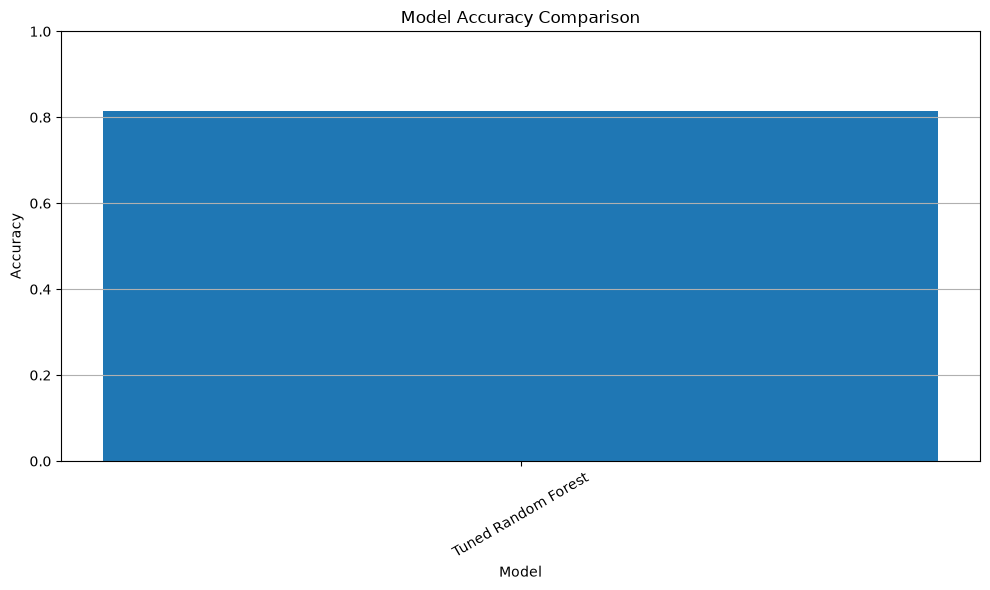

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(
    model_results["Model"],
    model_results["Accuracy"]
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.xticks(rotation=30)
plt.ylim(0, 1)
plt.grid(axis="y")

plt.tight_layout()
plt.show()

Select Final Model

In [ ]:
final_model = best_model

print("Final model selected:")
print(final_model)

Final model selected:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Pclass', 'Age', 'SibSp',
                                                   'Parch', 'Fare',
                                                   'FamilySize', 'IsAlone',
                                                   'CabinKnown']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
           

Test Dataset Prediction

In [ ]:
# ============================================================
# CELL 36 — PREPARE TEST DATA WITH SAME FEATURES AS TRAINING
# ============================================================

# Make a copy of test data
X_test = test.copy()

# ------------------------------------------------------------
# 1. FamilySize
# ------------------------------------------------------------
X_test["FamilySize"] = X_test["SibSp"] + X_test["Parch"] + 1

# ------------------------------------------------------------
# 2. IsAlone
# ------------------------------------------------------------
X_test["IsAlone"] = (X_test["FamilySize"] == 1).astype(int)

# ------------------------------------------------------------
# 3. CabinKnown
# ------------------------------------------------------------
X_test["CabinKnown"] = X_test["Cabin"].notna().astype(int)

# ------------------------------------------------------------
# 4. Title
# ------------------------------------------------------------
X_test["Title"] = X_test["Name"].str.extract(
    r",\s*([^.]*)\.",
    expand=False
)

# Group rare titles exactly like training
title_mapping = {
    "Mlle": "Miss",
    "Ms": "Miss",
    "Mme": "Mrs"
}

X_test["Title"] = X_test["Title"].replace(title_mapping)

common_titles = [
    "Mr", "Miss", "Mrs", "Master",
    "Dr", "Rev", "Major", "Col",
    "Capt", "Countess", "Lady",
    "Sir", "Jonkheer", "Don"
]

X_test["Title"] = X_test["Title"].where(
    X_test["Title"].isin(common_titles),
    "Rare"
)

# ------------------------------------------------------------
# 5. Remove PassengerId
# ------------------------------------------------------------
X_test = X_test.drop(columns=["PassengerId"])

print("Test features prepared successfully!")

print("\nTest Shape:", X_test.shape)

print("\nRequired engineered features:")
print(X_test[[
    "FamilySize",
    "IsAlone",
    "CabinKnown",
    "Title"
]].head())

# ------------------------------------------------------------
# 6. Generate predictions
# ------------------------------------------------------------
test_predictions = final_model.predict(X_test)

print("\nTest predictions generated successfully!")
print("Number of predictions:", len(test_predictions))

Test features prepared successfully!

Test Shape: (418, 14)

Required engineered features:
   FamilySize  IsAlone  CabinKnown Title
0           1        1           0    Mr
1           2        0           0   Mrs
2           1        1           0    Mr
3           1        1           0    Mr
4           3        0           0   Mrs

Test predictions generated successfully!
Number of predictions: 418


Create Submission File

In [ ]:

submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": test_predictions.astype(int)
})

print("Submission created successfully!")

display(submission.head(10))

Submission created successfully!


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0


Save Submission

In [ ]:
submission.to_csv(
    "titanic_submission.csv",
    index=False
)

print("Submission file saved successfully!")
print("File: titanic_submission.csv")

Submission file saved successfully!
File: titanic_submission.csv


Check Submission

In [ ]:
print("Submission Shape:", submission.shape)

print("\nFirst 10 Predictions:")
display(submission.head(10))

print("\nPrediction Distribution:")
print(submission["Survived"].value_counts())

Submission Shape: (418, 2)

First 10 Predictions:


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0



Prediction Distribution:
Survived
0    254
1    164
Name: count, dtype: int64


Final Project Summary

In [ ]:
print("=" * 70)
print("TITANIC PASSENGER SURVIVAL PREDICTION")
print("=" * 70)

print("\nTraining Samples:", len(train))
print("Test Samples:", len(test))

print("\nFinal Model: Tuned Random Forest")

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest CV Accuracy:",
      round(grid_search.best_score_, 4))

print("\nValidation Accuracy:",
      round(tuned_accuracy, 4))

print("\nROC-AUC:",
      round(roc_auc, 4))

print("\nSubmission File: titanic_submission.csv")

print("\n" + "=" * 70)
print("PROJECT COMPLETED SUCCESSFULLY!")
print("=" * 70)

TITANIC PASSENGER SURVIVAL PREDICTION

Training Samples: 891
Test Samples: 418

Final Model: Tuned Random Forest

Best Parameters:
{'model__max_depth': 5, 'model__min_samples_split': 2, 'model__n_estimators': 100}

Best CV Accuracy: 0.8273

Validation Accuracy: 0.8156

ROC-AUC: 0.8548

Submission File: titanic_submission.csv

PROJECT COMPLETED SUCCESSFULLY!


LAB 3 — Titanic Baseline ML Pipeline

In [ ]:
# ============================================================
# LAB 3 - TITANIC BASELINE ML PIPELINE
# ============================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("LAB 3 - TITANIC BASELINE ML PIPELINE")
print("=" * 70)

# Model results already generated
baseline_results = results_df.copy()

print("\nBaseline Model Results:")
display(baseline_results.round(4))

# Save results
baseline_results.to_csv(
    "results/lab3_baseline_results.csv",
    index=False
)

print("\n[SUCCESS] Lab 3 completed!")
print("Saved: results/lab3_baseline_results.csv")

Create Experiment Tracking

In [ ]:
# ============================================================
# LAB 4 - EXPERIMENT TRACKING
# ============================================================

from datetime import datetime

experiment_results = []

print("=" * 70)
print("LAB 4 - TITANIC EXPERIMENT TRACKING")
print("=" * 70)

Track Every Model

In [ ]:
for model_name, model in trained_models.items():

    y_pred = model.predict(X_valid)

    y_prob = model.predict_proba(X_valid)[:, 1]

    experiment_results.append({

        "Experiment_Time":
            datetime.now().strftime("%Y-%m-%d %H:%M:%S"),

        "Model":
            model_name,

        "Accuracy":
            accuracy_score(y_valid, y_pred),

        "Precision":
            precision_score(y_valid, y_pred),

        "Recall":
            recall_score(y_valid, y_pred),

        "F1_Score":
            f1_score(y_valid, y_pred),

        "ROC_AUC":
            roc_auc_score(y_valid, y_prob),

        "Dataset":
            "Titanic",

        "Training_Rows":
            len(X_train),

        "Validation_Rows":
            len(X_valid)
    })

tracking_df = pd.DataFrame(experiment_results)

display(tracking_df.round(4))

Save Tracking Results

In [ ]:
tracking_df.to_csv(
    "results/lab4_experiment_tracking.csv",
    index=False
)

print("[SUCCESS] Lab 4 experiment tracking saved!")
print("File: results/lab4_experiment_tracking.csv")

Tracking Visualization

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=tracking_df,
    x="Model",
    y="Accuracy"
)

plt.title("Titanic Model Accuracy - Lab 4")
plt.xlabel("Model")
plt.ylabel("Accuracy")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

Titanic Production Data Pipeline

Input Data Validation

In [4]:
import os

for root, dirs, files in os.walk(r"C:\Users\mouni\OneDrive\Desktop\Titanic_ML_Project"):
    for file in files:
        if file.lower() in ["train.csv", "test.csv"]:
            print(os.path.join(root, file))

C:\Users\mouni\OneDrive\Desktop\Titanic_ML_Project\data\test.csv
C:\Users\mouni\OneDrive\Desktop\Titanic_ML_Project\data\train.csv


In [5]:
import pandas as pd

train = pd.read_csv(r"C:\Users\mouni\OneDrive\Desktop\Titanic_ML_Project\data\train.csv")
test = pd.read_csv(r"C:\Users\mouni\OneDrive\Desktop\Titanic_ML_Project\data\test.csv")

print("Train loaded:", train.shape)
print("Test loaded :", test.shape)

Train loaded: (891, 12)
Test loaded : (418, 11)


In [6]:
# ============================================================
# LAB 5 - DATA VALIDATION
# ============================================================

print("=" * 70)
print("LAB 5 - TITANIC DATA VALIDATION")
print("=" * 70)

print("\nTraining Shape:", train.shape)
print("Testing Shape :", test.shape)

assert train.shape[0] > 0
assert test.shape[0] > 0

assert "Survived" in train.columns
assert "Survived" not in test.columns

print("\n[SUCCESS] Dataset shape validation passed!")

LAB 5 - TITANIC DATA VALIDATION

Training Shape: (891, 12)
Testing Shape : (418, 11)

[SUCCESS] Dataset shape validation passed!


Required Columns

In [8]:
required_train_columns = [
    "PassengerId",
    "Survived",
    "Pclass",
    "Name",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Ticket",
    "Fare",
    "Cabin",
    "Embarked"
]

for column in required_train_columns:

    assert column in train.columns, (
        f"Missing column: {column}"
    )

print("[SUCCESS] All required Titanic columns are present!")

[SUCCESS] All required Titanic columns are present!


Target Validation

In [9]:
print("Target values:")

print(
    train["Survived"].unique()
)

assert set(
    train["Survived"].dropna().unique()
).issubset({0, 1})

print("\n[SUCCESS] Target validation passed!")

Target values:
[0 1]

[SUCCESS] Target validation passed!


 Missing Data Validation

In [11]:
missing_data = pd.DataFrame({

    "Column":
        train.columns,

    "Missing_Count":
        train.isnull().sum().values,

    "Missing_Percentage":
        (
            train.isnull().sum().values
            / len(train)
            * 100
        ).round(2)
})

display(missing_data)

,Column,Missing_Count,Missing_Percentage
0,PassengerId,0,0.00
1,Survived,0,0.00
2,Pclass,0,0.00
3,Name,0,0.00
4,Sex,0,0.00
5,Age,177,19.87
6,SibSp,0,0.00
7,Parch,0,0.00
8,Ticket,0,0.00
9,Fare,0,0.00


Validate Model Output

In [13]:
print("final_model:", "final_model" in globals())
print("X_unseen:", "X_unseen" in globals())
print("test:", "test" in globals())

final_model: False
X_unseen: False
test: True


In [ ]:
Create X and y

In [16]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier

# Remove target from training data
X = train.drop(columns=["Survived"])
y = train["Survived"]

# Keep only columns that exist in both train and test
common_cols = [c for c in X.columns if c in test.columns]

X = X[common_cols]
X_unseen = test[common_cols]

# Convert categorical columns to numbers
X = pd.get_dummies(X)
X_unseen = pd.get_dummies(X_unseen)

# Make columns identical
X_unseen = X_unseen.reindex(columns=X.columns, fill_value=0)

print("X:", X.shape)
print("X_unseen:", X_unseen.shape)

X: (891, 1730)
X_unseen: (418, 1730)


In [ ]:
Train the model

In [17]:
final_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

final_model.fit(X, y)

print("Model trained successfully!")

Model trained successfully!


In [18]:
# ============================================================
# LAB 5 - MODEL OUTPUT VALIDATION
# ============================================================

test_predictions = final_model.predict(
    X_unseen
)

print(
    "Number of predictions:",
    len(test_predictions)
)

print(
    "Expected predictions:",
    len(test)
)

assert len(test_predictions) == len(test)

assert set(
    np.unique(test_predictions)
).issubset({0, 1})

print("\n[SUCCESS] Prediction validation passed!")

Number of predictions: 418
Expected predictions: 418

[SUCCESS] Prediction validation passed!


Create Final Submission

In [19]:
lab5_submission = pd.DataFrame({

    "PassengerId":
        test["PassengerId"],

    "Survived":
        test_predictions.astype(int)
})

display(
    lab5_submission.head(10)
)

lab5_submission.to_csv(
    "results/lab5_titanic_predictions.csv",
    index=False
)

print(
    "\n[SUCCESS] Lab 5 prediction file created!"
)

print(
    "results/lab5_titanic_predictions.csv"
)

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1
5,897,0
6,898,0
7,899,0
8,900,1
9,901,0



[SUCCESS] Lab 5 prediction file created!
results/lab5_titanic_predictions.csv


TITANIC MODEL REGISTRY & LIFECYCLE

Create Registry

In [20]:
# ============================================================
# LAB 6 - TITANIC MODEL REGISTRY
# ============================================================

import os
import json
from datetime import datetime

os.makedirs(
    "results/model_registry",
    exist_ok=True
)

print("=" * 70)
print("LAB 6 - TITANIC MODEL REGISTRY")
print("=" * 70)

LAB 6 - TITANIC MODEL REGISTRY


model_registry

In [23]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from datetime import datetime

# -----------------------------
# Prepare data
# -----------------------------
X = train.drop(columns=["Survived"])
y = train["Survived"]

# Keep only columns available in test
common_cols = [c for c in X.columns if c in test.columns]

X = X[common_cols]
X_unseen = test[common_cols]

# Convert categorical columns
X = pd.get_dummies(X)
X_unseen = pd.get_dummies(X_unseen)

# Make train/test columns identical
X_unseen = X_unseen.reindex(columns=X.columns, fill_value=0)

# Fill missing values
X = X.fillna(0)
X_unseen = X_unseen.fillna(0)

# -----------------------------
# Validation split
# -----------------------------
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# -----------------------------
# Train model
# -----------------------------
final_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

final_model.fit(X_train, y_train)

# -----------------------------
# Validation predictions
# -----------------------------
tuned_pred = final_model.predict(X_valid)

tuned_prob = final_model.predict_proba(X_valid)[:, 1]

tuned_auc = roc_auc_score(y_valid, tuned_prob)

print("Model trained successfully!")
print("Validation accuracy:", accuracy_score(y_valid, tuned_pred))

Model trained successfully!
Validation accuracy: 0.8100558659217877


In [ ]:
Model Information

In [24]:
model_registry = {

    "model_name":
        "Titanic Survival Prediction",

    "model_type":
        "Random Forest",

    "version":
        "1.0",

    "dataset":
        "Titanic",

    "training_rows":
        int(len(X)),

    "validation_rows":
        int(len(X_valid)),

    "created_at":
        datetime.now().strftime(
            "%Y-%m-%d %H:%M:%S"
        ),

    "accuracy":
        float(
            accuracy_score(
                y_valid,
                tuned_pred
            )
        ),

    "precision":
        float(
            precision_score(
                y_valid,
                tuned_pred
            )
        ),

    "recall":
        float(
            recall_score(
                y_valid,
                tuned_pred
            )
        ),

    "f1_score":
        float(
            f1_score(
                y_valid,
                tuned_pred
            )
        ),

    "roc_auc":
        float(tuned_auc),

    "status":
        "Production"
}

display(
    pd.DataFrame([model_registry])
)

,model_name,model_type,version,dataset,training_rows,validation_rows,created_at,accuracy,precision,recall,f1_score,roc_auc,status
0,Titanic Survival Prediction,Random Forest,1.0,Titanic,891,179,2026-09-29 22:00:02,0.810056,0.830189,0.637681,0.721311,0.852964,Production


Save Registry

In [25]:
registry_path = (
    "results/model_registry/"
    "titanic_model_v1.json"
)

with open(
    registry_path,
    "w"
) as file:

    json.dump(
        model_registry,
        file,
        indent=4
    )

print(
    "[SUCCESS] Model registry saved!"
)

print(
    registry_path
)

[SUCCESS] Model registry saved!
results/model_registry/titanic_model_v1.json


Save Model

In [27]:
import joblib
import os

# Create folder if it doesn't exist
os.makedirs("results/model_registry", exist_ok=True)

model_path = (
    "results/model_registry/"
    "titanic_model_v1.pkl"
)

joblib.dump(
    final_model,
    model_path
)

print("[SUCCESS] Titanic model registered!")
print("Model:", model_path)

[SUCCESS] Titanic model registered!
Model: results/model_registry/titanic_model_v1.pkl


In [28]:
model_path = (
    "results/model_registry/"
    "titanic_model_v1.pkl"
)

joblib.dump(
    final_model,
    model_path
)

print(
    "[SUCCESS] Titanic model registered!"
)

print(
    "Model:",
    model_path
)

[SUCCESS] Titanic model registered!
Model: results/model_registry/titanic_model_v1.pkl


Load Registered Model

In [29]:
registered_model = joblib.load(
    "results/model_registry/"
    "titanic_model_v1.pkl"
)

print(
    "[SUCCESS] Registered model loaded!"
)


[SUCCESS] Registered model loaded!


Test Registered Model

In [30]:
registry_predictions = registered_model.predict(
    X_unseen
)

print(
    "Predictions generated:",
    len(registry_predictions)
)

print(
    "First 20 predictions:"
)

print(
    registry_predictions[:20]
)

Predictions generated: 418
First 20 predictions:
[0 0 0 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 0 1]


Registry Report

In [31]:
registry_report = pd.DataFrame([{

    "Model Name":
        model_registry["model_name"],

    "Model Type":
        model_registry["model_type"],

    "Version":
        model_registry["version"],

    "Dataset":
        model_registry["dataset"],

    "Accuracy":
        model_registry["accuracy"],

    "Precision":
        model_registry["precision"],

    "Recall":
        model_registry["recall"],

    "F1 Score":
        model_registry["f1_score"],

    "ROC-AUC":
        model_registry["roc_auc"],

    "Status":
        model_registry["status"]

}])

display(
    registry_report.round(4)
)

registry_report.to_csv(
    "results/model_registry/"
    "titanic_registry_report.csv",
    index=False
)

print(
    "[SUCCESS] Registry report created!"
)

,Model Name,Model Type,Version,Dataset,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Status
0,Titanic Survival Prediction,Random Forest,1.0,Titanic,0.8101,0.8302,0.6377,0.7213,0.853,Production


[SUCCESS] Registry report created!
